# Realistic text-to-image (no interface, with download)

Type a prompt and get a **photorealistic, high-resolution** picture, then download it. It runs fully on open models from Hugging Face (no paid API):

- **RealVisXL V5.0**, a photoreal Stable Diffusion XL model (open RAIL++ license).
- **Hires pass:** after the first picture is made, it is enlarged 1.5x and re-detailed with the same model. This is the method the model's author recommends, and it adds real sharpness (skin, fabric, foliage, text on signs).

**Before you start (Colab):** Runtime → Change runtime type → **T4 GPU**. If Colab crashed earlier with "ran out of RAM", also choose **Runtime → Restart session**. Then run the cells from top to bottom, **each one only once**.
The first run downloads about 7 GB (one time per session). My estimate is 1 to 2 minutes per picture on a free T4.

## 1. Install

In [ ]:
!pip install -q -U diffusers transformers accelerate safetensors

## 2. Load the model

The model is loaded straight onto the GPU so the free Colab RAM isn't overloaded. Run this cell once.

In [ ]:
import gc, os, random, zipfile
from datetime import datetime

import torch
from PIL import Image
from PIL.PngImagePlugin import PngInfo
from IPython.display import display
from diffusers import (StableDiffusionXLPipeline, StableDiffusionXLImg2ImgPipeline,
                       AutoencoderKL, DPMSolverMultistepScheduler)

BASE_MODEL = "SG161222/RealVisXL_V5.0"       # photoreal SDXL model

device = "cuda" if torch.cuda.is_available() else "cpu"
dtype = torch.float16 if device == "cuda" else torch.float32
if device == "cpu":
    print("WARNING: no GPU found. In Colab: Runtime > Change runtime type > T4 GPU. On CPU this is far too slow.")
else:
    print("GPU:", torch.cuda.get_device_name(0))

def _load(cls, repo, **kw):
    """Load fp16 weights if the repo has them, otherwise the default weights. Uses little CPU memory."""
    try:
        return cls.from_pretrained(repo, variant="fp16", use_safetensors=True, low_cpu_mem_usage=True, **kw)
    except Exception:
        return cls.from_pretrained(repo, use_safetensors=True, low_cpu_mem_usage=True, **kw)

# fp16-safe VAE (avoids black or noisy images), moved to the GPU right away
vae = AutoencoderKL.from_pretrained("madebyollin/sdxl-vae-fp16-fix", torch_dtype=dtype).to(device)
gc.collect()

pipe_args = dict(vae=vae, torch_dtype=dtype, add_watermarker=False)
pipe, on_gpu = None, False
if device == "cuda":
    try:
        pipe = _load(StableDiffusionXLPipeline, BASE_MODEL, device_map="cuda", **pipe_args)   # straight to the GPU
        on_gpu = True
    except Exception as e:
        print("Direct-to-GPU loading is not available in this diffusers version, loading normally:", str(e)[:80])
if pipe is None:
    pipe = _load(StableDiffusionXLPipeline, BASE_MODEL, **pipe_args)
if not on_gpu:
    pipe.to(device)
gc.collect()

# Sampler recommended by the model's author: DPM++ SDE Karras
pipe.scheduler = DPMSolverMultistepScheduler.from_config(
    pipe.scheduler.config, algorithm_type="sde-dpmsolver++", use_karras_sigmas=True)
if device == "cuda":
    pipe.vae.enable_tiling()                  # lets the larger hires picture fit in GPU memory

# Second pass that re-details the enlarged picture (shares the same weights, no extra memory)
try:
    refiner = StableDiffusionXLImg2ImgPipeline.from_pipe(pipe)
except Exception as e:
    refiner = None
    print("Hires pass is not available in this setup (pictures will still be generated):", str(e)[:80])
print("Ready:", BASE_MODEL)

GPU: Tesla T4


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


config.json:   0%|          | 0.00/631 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors: reconstructing file:   0%|          |  0.00B /  335MB            

diffusion_pytorch_model.safetensors: downloading bytes:           |  0.00B            

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


... (4 outputs left out)

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

There are modules in UNet2DConditionModel that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


Ready: SG161222/RealVisXL_V5.0


## 3. The generator

`generate()` makes the pictures and saves them in the `outputs/` folder. Image shapes use sizes SDXL was trained on, which gives the best quality:

| shape | size |
|---|---|
| `square` | 1024 x 1024 |
| `portrait` | 832 x 1216 |
| `landscape` | 1216 x 832 |
| `wide` | 1344 x 768 |
| `tall` | 768 x 1344 |

With the hires pass on, the final picture is 1.5 times larger (for example `square` becomes 1536 x 1536).

In [ ]:
os.makedirs("outputs", exist_ok=True)

SIZES = {"square": (1024, 1024), "portrait": (832, 1216), "landscape": (1216, 832),
         "wide": (1344, 768), "tall": (768, 1344)}

REALISM = "RAW photo, photorealistic, natural lighting, sharp focus, highly detailed, professional photography, 8k uhd"
DEFAULT_NEGATIVE = ("cartoon, illustration, painting, drawing, anime, 3d render, cgi, plastic skin, blurry, lowres, "
                    "bad anatomy, bad hands, extra fingers, deformed, face asymmetry, eyes asymmetry, "
                    "deformed eyes, deformed mouth, watermark, text, logo")

def _save(image, prompt, seed):
    meta = PngInfo()                                       # remove these 3 lines if you do not want the
    meta.add_text("prompt", prompt)                        # prompt and seed stored inside the saved file
    meta.add_text("seed", str(seed))
    path = f"outputs/image_{datetime.now():%Y%m%d_%H%M%S}_{seed}.png"
    image.save(path, pnginfo=meta)
    return path

def generate(prompt, negative_prompt="", n_images=1, shape="square", steps=35, guidance=5.5, seed=-1,
             realism_boost=True, hires=True, hires_scale=1.5, hires_strength=0.3):
    """Returns a list of (PIL image, saved file path)."""
    width, height = SIZES[shape]
    pos = f"{prompt}, {REALISM}" if realism_boost else prompt
    neg = ", ".join(x for x in (negative_prompt.strip() if negative_prompt else "",
                                DEFAULT_NEGATIVE if realism_boost else "") if x)
    seed = int(seed)
    if seed < 0:
        seed = random.randint(0, 2**31 - 1)

    oom = getattr(torch.cuda, "OutOfMemoryError", RuntimeError)
    results = []
    for i in range(int(n_images)):
        s = seed + i                                       # each picture uses its own seed (seed, seed+1, ...)
        gen = torch.Generator(device=device).manual_seed(s)
        try:
            image = pipe(prompt=pos, negative_prompt=neg, width=width, height=height,
                         num_inference_steps=int(steps), guidance_scale=float(guidance), generator=gen).images[0]
        except oom:
            gc.collect(); torch.cuda.empty_cache()
            raise RuntimeError("Out of GPU memory. Restart the session (Runtime > Restart session) and run again.")

        if hires and refiner is not None:
            try:
                w, h = image.size
                big = image.resize((int(w * hires_scale) // 8 * 8, int(h * hires_scale) // 8 * 8), Image.LANCZOS)
                gen2 = torch.Generator(device=device).manual_seed(s)
                image = refiner(prompt=pos, negative_prompt=neg, image=big, strength=float(hires_strength),
                                num_inference_steps=max(int(steps), 40), guidance_scale=float(guidance),
                                generator=gen2).images[0]
            except oom:
                gc.collect(); torch.cuda.empty_cache()
                print("Not enough GPU memory for the hires pass, keeping the normal-size picture.")

        results.append((image, _save(image, prompt, s)))
        gc.collect()
        if device == "cuda":
            torch.cuda.empty_cache()
    return results

def download(results):
    """One picture downloads as a PNG. Several pictures download as one zip (avoids browser pop-up blocking)."""
    paths = [p for _, p in results]
    if len(paths) > 1:
        zip_path = f"outputs/images_{datetime.now():%Y%m%d_%H%M%S}.zip"
        with zipfile.ZipFile(zip_path, "w") as z:
            for p in paths:
                z.write(p, os.path.basename(p))
        target = zip_path
    else:
        target = paths[0]
    try:                                                   # in Colab this starts a browser download
        from google.colab import files
        files.download(target)
    except ImportError:
        print("Not in Colab: the files are in the 'outputs' folder next to this notebook.")
    print("Download:", target)

## 4. Generate

Run the cell and answer the questions. Press **Enter** to keep the default shown in brackets. The pictures appear below and download automatically (several pictures come as one zip file).

Describe the picture you want: An elderly fisherman mending a net on a wooden pier at sunrise, weathered skin, soft golden light, shot on a 85mm lens, shallow depth of field.
Anything to avoid? (press Enter to skip): 
Shape (square, portrait, landscape, wide, tall) [Enter = square]: square
Number of pictures [1-4, Enter = 1]: 1
Extra detail pass for higher quality? Slower. (y/n) [Enter = y]: y
Seed (-1 = random, use the same number to repeat a result) [-1-2147483647, Enter = -1]: -1
Generating... this takes a minute or two per picture.


  0%|          | 0/35 [00:00<?, ?it/s]

  0%|          | 0/12 [00:00<?, ?it/s]

Not enough GPU memory for the hires pass, keeping the normal-size picture.


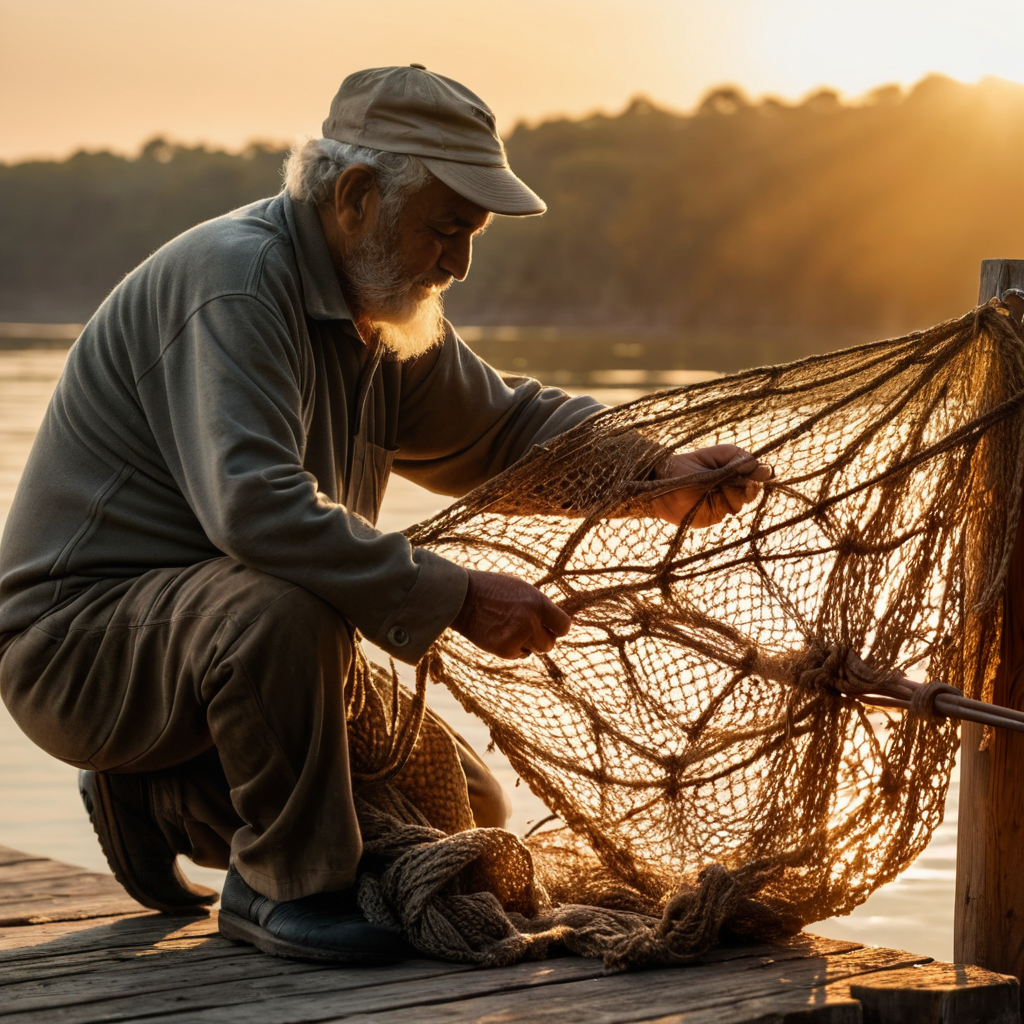

Saved: outputs/image_20261109_060349_1647135049.png | size: (1024, 1024)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download: outputs/image_20261109_060349_1647135049.png


In [ ]:
def ask_number(question, default, low, high, cast=float):
    while True:
        text = input(f"{question} [{low}-{high}, Enter = {default}]: ").strip()
        if not text:
            return default
        try:
            value = cast(text)
            if low <= value <= high:
                return value
        except ValueError:
            pass
        print(f"  Please type a number between {low} and {high}.")

def ask_choice(question, options, default):
    while True:
        text = input(f"{question} ({', '.join(options)}) [Enter = {default}]: ").strip().lower()
        if not text:
            return default
        if text in options:
            return text
        print("  Please type one of:", ", ".join(options))

prompt = input("Describe the picture you want: ").strip()
while not prompt:
    prompt = input("The prompt can't be empty. Describe the picture you want: ").strip()

negative = input("Anything to avoid? (press Enter to skip): ").strip()
shape    = ask_choice("Shape", list(SIZES), "square")
n_images = ask_number("Number of pictures", 1, 1, 4, int)
hires    = input("Extra detail pass for higher quality? Slower. (y/n) [Enter = y]: ").strip().lower() != "n"
seed     = ask_number("Seed (-1 = random, use the same number to repeat a result)", -1, -1, 2**31 - 1, int)

print("Generating... this takes a minute or two per picture.")
results = generate(prompt, negative, n_images=n_images, shape=shape, hires=hires, seed=seed)
for image, path in results:
    display(image)
    print("Saved:", path, "| size:", image.size)
download(results)

## Tips for the most realistic results

- **Write like a photographer**, in a sentence or two: subject, place, light, lens, mood. For example: *"An elderly fisherman mending a net on a wooden pier at sunrise, weathered skin, soft golden light, shot on a 85mm lens, shallow depth of field."*
- **Be specific** about clothing, materials and time of day. Vague prompts give generic pictures.
- **Try several seeds.** Set "Number of pictures" to 3 or 4 and keep the best one. Hands and small details can fail in some of them.
- Use `portrait` for people, `landscape` or `wide` for scenery and interiors.
- To repeat or fine-tune a result you liked, reuse its seed (it is in the file name) and change the prompt a little.
- If you see a "GPU out of memory" message, restart the session, run the cells again, and answer **n** to the extra detail pass.